# 05. Temporal Dynamics, Seasonality & Spatial Variations

> **Role**: Role 2 — Dataset Collection & EDA  
> **Project**: Project 18 — Water Quality Prediction via Gradient Boosting & DNN  
> **Course**: Semester 5 AML / DL  

Uncovers historical multi-decade trends (1940–2023), monthly seasonal environmental cycles, and waterbody hydrological contrasts.

---

## 1. Setup & Environment

In [ ]:
# Setup and Parse Dates
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
df = pd.read_parquet(DATA_PATH)
df['ParsedDate'] = pd.to_datetime(df['Date'], format='%d-%m-%Y', errors='coerce')
df['Year'] = df['ParsedDate'].dt.year
df['Month'] = df['ParsedDate'].dt.month
print(f"Loaded {len(df):,} records with parsed temporal coordinates.")

Loaded 4,297,895 records with parsed temporal coordinates.


## 2. Multi-Decade Historical Environmental Trajectory (1950–2023)
Tracks long-term annual median water quality index over time.

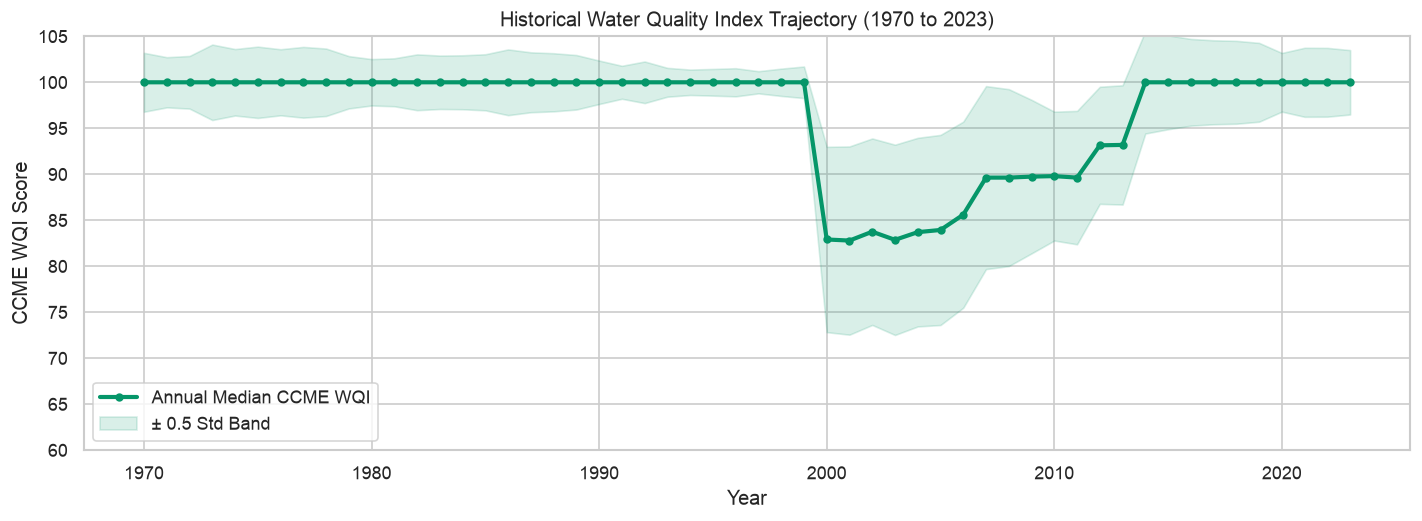

In [ ]:
# Multi-Decade Water Quality Trajectory
annual_trends = df[(df['Year'] >= 1970) & (df['Year'] <= 2023)].groupby('Year')['CCME_Values'].agg(['mean', 'median', 'std', 'count'])

plt.figure(figsize=(12, 4.5))
plt.plot(annual_trends.index, annual_trends['median'], color='#059669', lw=2.5, marker='o', ms=4, label='Annual Median CCME WQI')
plt.fill_between(annual_trends.index, annual_trends['median'] - annual_trends['std']*0.5, 
                 annual_trends['median'] + annual_trends['std']*0.5, color='#059669', alpha=0.15, label='± 0.5 Std Band')

plt.title('Historical Water Quality Index Trajectory (1970 to 2023)')
plt.xlabel('Year')
plt.ylabel('CCME WQI Score')
plt.ylim(60, 105)
plt.legend()
plt.tight_layout()
plt.show()

annual_trends.tail(10)

## 3. Monthly Seasonal Periodicities
Reveals spring agricultural nutrient runoff, summer temperature surges, and winter dissolved oxygen peaks.

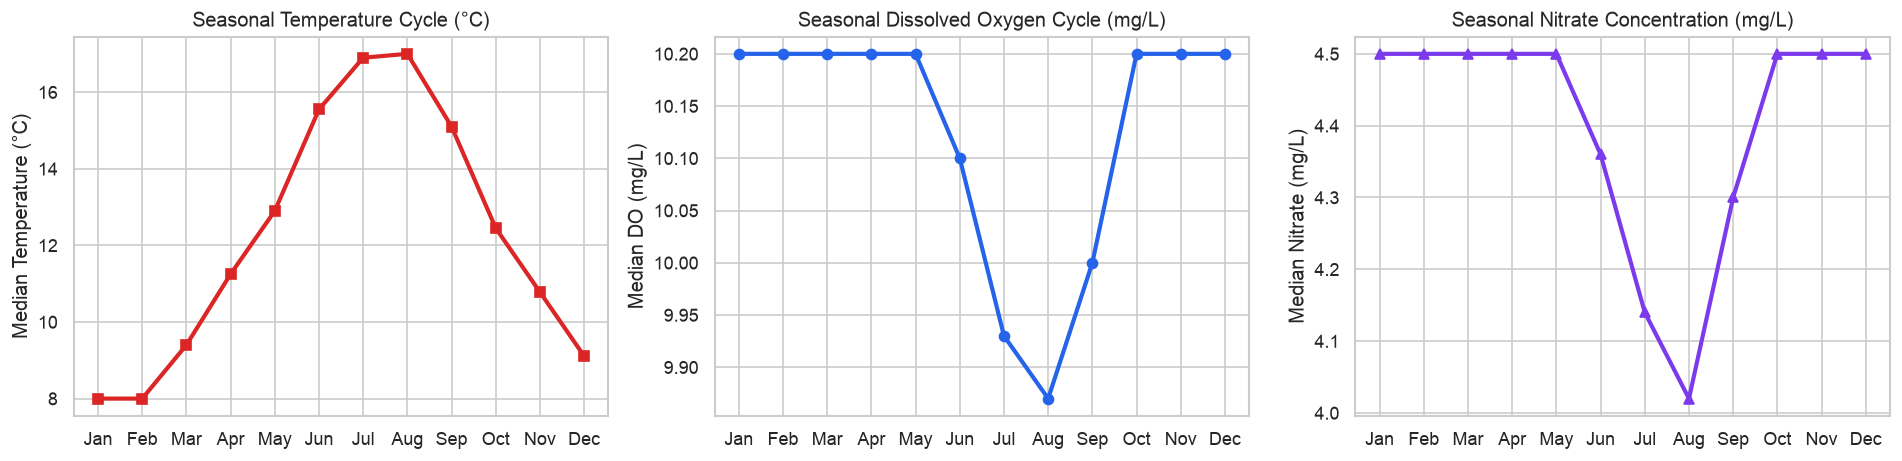

In [ ]:
# Monthly Seasonal Dynamics
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
monthly_chem = df.groupby('Month')[['Temperature (cel)', 'Dissolved Oxygen (mg/l)', 'Nitrate (mg/l)']].median()
monthly_chem.index = month_names

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Temp
axes[0].plot(monthly_chem.index, monthly_chem['Temperature (cel)'], color='#dc2626', lw=2.5, marker='s')
axes[0].set_title('Seasonal Temperature Cycle (°C)')
axes[0].set_ylabel('Median Temperature (°C)')

# DO
axes[1].plot(monthly_chem.index, monthly_chem['Dissolved Oxygen (mg/l)'], color='#2563eb', lw=2.5, marker='o')
axes[1].set_title('Seasonal Dissolved Oxygen Cycle (mg/L)')
axes[1].set_ylabel('Median DO (mg/L)')

# Nitrate
axes[2].plot(monthly_chem.index, monthly_chem['Nitrate (mg/l)'], color='#7c3aed', lw=2.5, marker='^')
axes[2].set_title('Seasonal Nitrate Concentration (mg/L)')
axes[2].set_ylabel('Median Nitrate (mg/L)')

plt.tight_layout()
plt.show()

## 4. Waterbody Comparison: Flowing Streams vs Lakes vs Effluent
Analyzes water quality across hydrological categories.

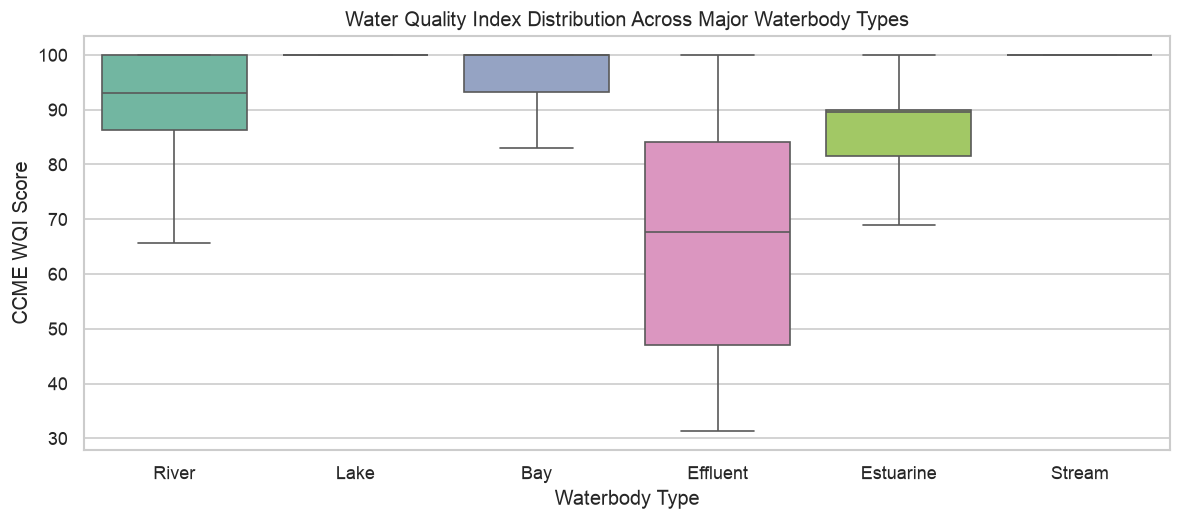

In [ ]:
# Waterbody Comparison
top_wb = df['Waterbody Type'].value_counts().head(6).index
wb_subset = df[df['Waterbody Type'].isin(top_wb)]

plt.figure(figsize=(10, 4.5))
sns.boxplot(data=wb_subset, x='Waterbody Type', y='CCME_Values', palette='Set2', hue='Waterbody Type', legend=False, showfliers=False)
plt.title('Water Quality Index Distribution Across Major Waterbody Types')
plt.xlabel('Waterbody Type')
plt.ylabel('CCME WQI Score')
plt.tight_layout()
plt.show()

wb_subset.groupby('Waterbody Type')['CCME_Values'].agg(['mean', 'median', 'std', 'count'])

## 5. Export Spatiotemporal Aggregates Dataset

In [ ]:
# Export Spatiotemporal Parquet
out_path = os.path.join(OUT_DIR, '05_temporal_spatial_aggregates.parquet')
monthly_chem.reset_index().to_parquet(out_path, index=False, compression='snappy')
print(f"Exported Spatiotemporal Aggregates to: {out_path} ({os.path.getsize(out_path)} bytes)")

Exported Spatiotemporal Aggregates to: data/GeneratedOutput/01.EDA/05_temporal_spatial_aggregates.parquet (3278 bytes)
